In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Notebook 05: Final Test Evaluation

## Campus Road Damage Detection and Severity-Aware Maintenance Prioritization

### Objective

Evaluate the selected YOLOv8n-AdamW model on the
independent test dataset to assess its generalization
performance on unseen road damage images.

### Selected Model

- Architecture: YOLOv8n
- Optimizer: AdamW
- Completed Training Epochs: 16
- Validation mAP50: 44.30%
- Validation mAP50-95: 20.81%

### Evaluation Metrics

- Precision
- Recall
- mAP50
- mAP50-95
- Class-wise detection performance
- Confusion matrix
- Inference speed

## Step 1: Project Setup and Input Verification

In [1]:
# ==========================================
# NOTEBOOK 05 - CELL 1
# Project Setup and Input Verification
# ==========================================

import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. Define Directories
# ==========================================

INPUT_DIR = Path("/kaggle/input")

WORK_DIR = Path("/kaggle/working")

DATASET_PATH = Path(
    "/kaggle/input/datasets/ammritkumaar/"
    "rdd2022-preprocessed-yolo"
)

PROJECT_DIR = WORK_DIR / "Final_Test_Evaluation"

PROJECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("========== PROJECT SETUP ==========")

print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

print("\nWorking directory:", WORK_DIR)
print("Evaluation directory:", PROJECT_DIR)

assert DATASET_PATH.exists(), "Dataset not found!"

# ==========================================
# 2. Check GPU
# ==========================================

print("\n========== GPU CHECK ==========")

print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

assert torch.cuda.is_available(), "GPU not available!"

for i in range(torch.cuda.device_count()):

    print(f"GPU {i}:", torch.cuda.get_device_name(i))

# ==========================================
# 3. Locate Selected Best Model
# ==========================================

print("\n========== SELECTED MODEL ==========")

model_files = sorted(
    INPUT_DIR.rglob("best_model.pt")
)

assert len(model_files) > 0, "Selected model not found!"

for i, file in enumerate(model_files, 1):

    size_mb = file.stat().st_size / (1024 ** 2)

    print(f"\nModel {i}:")
    print("Path:", file)
    print(f"Size: {size_mb:.2f} MB")

# ==========================================
# 4. Locate Model Selection Summary
# ==========================================

print("\n========== MODEL SELECTION SUMMARY ==========")

selection_files = sorted(
    INPUT_DIR.rglob("model_selection.json")
)

for file in selection_files:

    print(file)

# ==========================================
# 5. Locate Validation Comparison Results
# ==========================================

print("\n========== VALIDATION RESULTS ==========")

comparison_files = sorted(
    INPUT_DIR.rglob("overall_comparison.csv")
)

for file in comparison_files:

    print(file)

print("\n========== SETUP COMPLETED ==========")

========== PROJECT SETUP ==========
Dataset path: /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo
Dataset exists: True

Working directory: /kaggle/working
Evaluation directory: /kaggle/working/Final_Test_Evaluation

========== GPU CHECK ==========
CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

========== SELECTED MODEL ==========

Model 1:
Path: /kaggle/input/notebooks/ammritkumaar/04-validation-evaluation/Validation_Evaluation/Selected_Model/best_model.pt
Size: 30.32 MB

Model 2:
Path: /kaggle/input/notebooks/ammritkumaar/04-validation-evaluation/Validation_Evaluation_Backup/Validation_Evaluation/Selected_Model/best_model.pt
Size: 30.32 MB

========== MODEL SELECTION SUMMARY ==========
/kaggle/input/notebooks/ammritkumaar/04-validation-evaluation/Validation_Evaluation/Selected_Model/model_selection.json
/kaggle/input/notebooks/ammritkumaar/04-validation-evaluation/Validation_Evaluation_Backup/Validation_Evaluation/Selected_Model/model_selection.json



## Step 2: Configure Selected Model and Test Dataset

Load the best-performing YOLOv8n-AdamW checkpoint
selected during validation evaluation.

Verify the independent test dataset containing
2,377 images and their corresponding YOLO labels.

Create a dataset configuration file for final test
evaluation without modifying the original dataset.

In [2]:
# ==========================================
# NOTEBOOK 05 - CELL 2
# Configure Selected Model and Test Dataset
# ==========================================

import json
import yaml
from pathlib import Path

# ==========================================
# 1. Configure Selected Model
# ==========================================

SELECTED_MODEL_DIR = Path(
    "/kaggle/input/notebooks/ammritkumaar/"
    "04-validation-evaluation/"
    "Validation_Evaluation/Selected_Model"
)

MODEL_PATH = SELECTED_MODEL_DIR / "best_model.pt"

SELECTION_PATH = (
    SELECTED_MODEL_DIR / "model_selection.json"
)

assert MODEL_PATH.exists(), "Model not found!"
assert SELECTION_PATH.exists(), "Selection summary not found!"

print("========== SELECTED MODEL ==========")

print("Model path:", MODEL_PATH)

print(
    f"Model size: "
    f"{MODEL_PATH.stat().st_size / (1024 ** 2):.2f} MB"
)

# Load model selection summary
with open(SELECTION_PATH, "r") as f:

    selection_summary = json.load(f)

print("\n========== MODEL SELECTION DETAILS ==========")

print(
    "Selected model:",
    selection_summary["selected_model"]
)

print(
    "Completed epochs:",
    selection_summary["completed_epochs"]
)

print(
    "Validation mAP50:",
    round(selection_summary["mAP50"] * 100, 2),
    "%"
)

print(
    "Validation mAP50-95:",
    round(selection_summary["mAP50-95"] * 100, 2),
    "%"
)

assert selection_summary["selected_model"] == "YOLOv8n-AdamW"

# ==========================================
# 2. Verify Test Dataset
# ==========================================

TEST_IMAGES_DIR = DATASET_PATH / "images/test"

TEST_LABELS_DIR = DATASET_PATH / "labels/test"

assert TEST_IMAGES_DIR.exists()
assert TEST_LABELS_DIR.exists()

valid_extensions = {".jpg", ".jpeg", ".png"}

test_images = sorted([

    p for p in TEST_IMAGES_DIR.iterdir()

    if p.is_file()
    and p.suffix.lower() in valid_extensions
])

test_labels = sorted(
    TEST_LABELS_DIR.glob("*.txt")
)

print("\n========== TEST DATASET ==========")

print("Test images:", len(test_images))
print("Test labels:", len(test_labels))

assert len(test_images) == 2377
assert len(test_labels) == 2377

# ==========================================
# 3. Verify Image-Label Matching
# ==========================================

image_stems = {
    p.stem for p in test_images
}

label_stems = {
    p.stem for p in test_labels
}

missing_labels = image_stems - label_stems

missing_images = label_stems - image_stems

print("\n========== IMAGE-LABEL VERIFICATION ==========")

print("Images without labels:", len(missing_labels))

print("Labels without images:", len(missing_images))

assert len(missing_labels) == 0
assert len(missing_images) == 0

# ==========================================
# 4. Create Test Evaluation YAML
# ==========================================

test_config = {

    "path": str(DATASET_PATH),

    "train": "images/train",

    "val": "images/val",

    "test": "images/test",

    "nc": 4,

    "names": {

        0: "Longitudinal Crack",

        1: "Transverse Crack",

        2: "Alligator Crack",

        3: "Pothole"
    }
}

TEST_YAML_PATH = WORK_DIR / "test_data.yaml"

with open(TEST_YAML_PATH, "w") as f:

    yaml.safe_dump(
        test_config,
        f,
        sort_keys=False
    )

print("\n========== TEST DATA CONFIGURATION ==========")

print("YAML saved at:", TEST_YAML_PATH)

with open(TEST_YAML_PATH, "r") as f:

    print(f.read())

print("========== TEST DATASET CONFIGURATION COMPLETED ==========")

========== SELECTED MODEL ==========
Model path: /kaggle/input/notebooks/ammritkumaar/04-validation-evaluation/Validation_Evaluation/Selected_Model/best_model.pt
Model size: 30.32 MB

========== MODEL SELECTION DETAILS ==========
Selected model: YOLOv8n-AdamW
Completed epochs: 16
Validation mAP50: 44.3 %
Validation mAP50-95: 20.81 %

========== TEST DATASET ==========
Test images: 2377
Test labels: 2377

========== IMAGE-LABEL VERIFICATION ==========
Images without labels: 0
Labels without images: 0

========== TEST DATA CONFIGURATION ==========
YAML saved at: /kaggle/working/test_data.yaml
path: /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Pothole

========== TEST DATASET CONFIGURATION COMPLETED ==========


## Step 3: Install Ultralytics and Verify Environment

Install the same Ultralytics version used during
training and validation.

Load the selected YOLOv8n-AdamW model and verify
the GPU environment and test evaluation settings
before performing final test evaluation.

In [3]:
# ==========================================
# NOTEBOOK 05 - CELL 3
# Install Ultralytics and Environment Setup
# ==========================================

# Install same version used in previous notebooks
!pip install -q ultralytics==8.4.211

import torch
import ultralytics
from ultralytics import YOLO

# ==========================================
# 1. Environment Verification
# ==========================================

print("========== ENVIRONMENT CHECK ==========")

print("PyTorch Version:", torch.__version__)
print("Ultralytics Version:", ultralytics.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

assert torch.cuda.is_available(), "GPU not available!"

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

# ==========================================
# 2. Test Evaluation Settings
# ==========================================

IMG_SIZE = 640
BATCH_SIZE = 32
DEVICE = 0

print("\n========== EVALUATION SETTINGS ==========")

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Device:", DEVICE)
print("Evaluation Split: test")

# ==========================================
# 3. Verify Required Files
# ==========================================

assert MODEL_PATH.exists()
assert TEST_YAML_PATH.exists()
assert TEST_IMAGES_DIR.exists()
assert TEST_LABELS_DIR.exists()

print("\n========== FILE VERIFICATION ==========")

print("Selected Model:", MODEL_PATH.exists())
print("Test YAML:", TEST_YAML_PATH.exists())
print("Test Images Directory:", TEST_IMAGES_DIR.exists())
print("Test Labels Directory:", TEST_LABELS_DIR.exists())

# ==========================================
# 4. Load Selected Model
# ==========================================

print("\n========== LOADING SELECTED MODEL ==========")

model = YOLO(str(MODEL_PATH))

print("YOLOv8n-AdamW loaded successfully!")

print("\nModel Classes:", model.names)

expected_classes = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Pothole"
}

assert model.names == expected_classes

print("All 4 model classes verified!")

print("\n========== ENVIRONMENT READY ==========")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
========== ENVIRONMENT CHECK ==========
PyTorch Version: 2.11.0+cu130
Ultralytics Version: 8.4.211
CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

========== EVALUATION SETTINGS ==========
Image Size: 640
Batch Size: 32
Device: 0
Evaluation Split: test

========== FILE VERIFICATION ==========
Selected Model: True
Test YAML: True
Test Images Directory: True
Test Labels Directory: True

========== LOADING SELECTED MODEL ==========
YOLOv8n-AdamW loaded successfully!

Model Classes: {0: 'Longitudinal Crack', 1: 'Transverse Crack', 2: 'Alligator Crack', 3: 'Pothole'}
All 4 model classes verified!

========== ENVIRONMENT READY ==========


## Step 4: Final Test Evaluation

Evaluate the selected YOLOv8n-AdamW model on the
independent test dataset containing 2,377 images.

Calculate overall and class-wise detection metrics,
including Precision, Recall, mAP50, and mAP50-95.

Generate confusion matrices, performance curves,
prediction samples, and inference speed statistics.

No additional training or model tuning is performed
using the test dataset.

In [4]:
# ==========================================
# NOTEBOOK 05 - CELL 4
# Final Test Evaluation
# ==========================================

import time
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

print("========== FINAL TEST EVALUATION ==========")

print("Model: YOLOv8n-AdamW")
print("Completed Training Epochs: 16")
print("Expected Test Images: 2377")

# Load selected trained model
model = YOLO(str(MODEL_PATH))

# Record evaluation start time
start_time = time.time()

# ==========================================
# 1. Run Final Test Evaluation
# ==========================================

test_metrics = model.val(

    data=str(TEST_YAML_PATH),

    split="test",

    imgsz=IMG_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=2,

    conf=0.001,

    iou=0.7,

    max_det=300,

    half=True,

    plots=True,

    project=str(PROJECT_DIR),

    name="AdamW_Final_Test",

    exist_ok=True,

    verbose=True
)

# Calculate evaluation time
test_eval_time = time.time() - start_time

# ==========================================
# 2. Overall Test Metrics
# ==========================================

test_overall = pd.DataFrame({

    "Model": ["YOLOv8n-AdamW"],

    "Precision": [test_metrics.box.mp],

    "Recall": [test_metrics.box.mr],

    "mAP50": [test_metrics.box.map50],

    "mAP50-95": [test_metrics.box.map],

    "Evaluation Time (min)": [
        test_eval_time / 60
    ],

    "Inference Time (ms/image)": [
        test_metrics.speed["inference"]
    ]
})

print("\n========== FINAL TEST METRICS ==========")

display(test_overall.round(5))

# ==========================================
# 3. Class-wise Test Metrics
# ==========================================

class_results = []

for i, class_id in enumerate(
    test_metrics.box.ap_class_index
):

    class_id = int(class_id)

    class_results.append({

        "Class ID": class_id,

        "Class Name": model.names[class_id],

        "Precision": test_metrics.box.p[i],

        "Recall": test_metrics.box.r[i],

        "mAP50": test_metrics.box.ap50[i],

        "mAP50-95": test_metrics.box.ap[i]
    })

test_classwise = pd.DataFrame(class_results)

print("\n========== CLASS-WISE TEST METRICS ==========")

display(test_classwise.round(5))

# ==========================================
# 4. Display Final Performance in Percentage
# ==========================================

print("\n========== FINAL MODEL PERFORMANCE ==========")

print(
    f"Test Precision: "
    f"{test_metrics.box.mp * 100:.2f}%"
)

print(
    f"Test Recall: "
    f"{test_metrics.box.mr * 100:.2f}%"
)

print(
    f"Test mAP50: "
    f"{test_metrics.box.map50 * 100:.2f}%"
)

print(
    f"Test mAP50-95: "
    f"{test_metrics.box.map * 100:.2f}%"
)

# ==========================================
# 5. Save Test Evaluation Results
# ==========================================

TEST_RESULTS_DIR = Path(test_metrics.save_dir)

test_overall.to_csv(

    TEST_RESULTS_DIR / "test_overall_metrics.csv",

    index=False
)

test_classwise.to_csv(

    TEST_RESULTS_DIR / "test_classwise_metrics.csv",

    index=False
)

# ==========================================
# 6. Evaluation Time and Inference Speed
# ==========================================

print("\n========== SPEED STATISTICS ==========")

print(
    f"Total Evaluation Time: "
    f"{test_eval_time / 60:.2f} minutes"
)

print(
    f"Preprocessing Time: "
    f"{test_metrics.speed['preprocess']:.2f} ms/image"
)

print(
    f"Inference Time: "
    f"{test_metrics.speed['inference']:.2f} ms/image"
)

print(
    f"Postprocessing Time: "
    f"{test_metrics.speed['postprocess']:.2f} ms/image"
)

# ==========================================
# 7. Display Saved Files
# ==========================================

print("\n========== SAVED TEST RESULTS ==========")

print("Results directory:", TEST_RESULTS_DIR)

for file in sorted(TEST_RESULTS_DIR.iterdir()):

    print(file.name)

print("\n========== FINAL TEST EVALUATION COMPLETED ==========")

========== FINAL TEST EVALUATION ==========
Model: YOLOv8n-AdamW
Completed Training Epochs: 16
Expected Test Images: 2377
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.0 ms, read: 3.1±4.5 MB/s, size: 249.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels/test... 2377 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2377/2377 18.6it/s 2:080.2sss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP

,Model,Precision,Recall,mAP50,mAP50-95,Evaluation Time (min),Inference Time (ms/image)
0,YOLOv8n-AdamW,0.54368,0.44376,0.45036,0.21191,4.03361,3.08357



========== CLASS-WISE TEST METRICS ==========


,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
0,0,Longitudinal Crack,0.53806,0.45233,0.45073,0.22688
1,1,Transverse Crack,0.53897,0.44750,0.45136,0.19971
2,2,Alligator Crack,0.59391,0.54934,0.57666,0.29075
3,3,Pothole,0.50378,0.32588,0.32271,0.13031



========== FINAL MODEL PERFORMANCE ==========
Test Precision: 54.37%
Test Recall: 44.38%
Test mAP50: 45.04%
Test mAP50-95: 21.19%

========== SPEED STATISTICS ==========
Total Evaluation Time: 4.03 minutes
Preprocessing Time: 0.70 ms/image
Inference Time: 3.08 ms/image
Postprocessing Time: 1.08 ms/image

========== SAVED TEST RESULTS ==========
Results directory: /kaggle/working/Final_Test_Evaluation/AdamW_Final_Test
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
test_classwise_metrics.csv
test_overall_metrics.csv
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

========== FINAL TEST EVALUATION COMPLETED ==========


## Step 5: Detection Accuracy and F1-Score

Calculate True Positives, False Positives, and False
Negatives by matching predicted bounding boxes with
ground-truth bounding boxes.

Evaluation settings:
- Confidence threshold: 0.25
- IoU threshold: 0.50
- One-to-one bounding box matching
- Correct class matching required

Calculate overall and class-wise Detection Accuracy,
Precision, Recall, and F1-Score.

Detection Accuracy = TP / (TP + FP + FN)

Note: Detection Accuracy is a custom object detection
metric, not conventional classification accuracy.

In [6]:
# Clear GPU memory after OOM error

import gc
import torch

if "results" in globals():
    del results

if "model" in globals():
    del model

gc.collect()

torch.cuda.empty_cache()

print("========== GPU MEMORY CLEANUP ==========")

for i in range(torch.cuda.device_count()):

    free, total = torch.cuda.mem_get_info(i)

    print(f"\nGPU {i}: {torch.cuda.get_device_name(i)}")

    print(f"Free Memory: {free / 1024**3:.2f} GB")

    print(f"Total Memory: {total / 1024**3:.2f} GB")

print("\nGPU memory cleanup completed!")

========== GPU MEMORY CLEANUP ==========

GPU 0: Tesla T4
Free Memory: 3.51 GB
Total Memory: 14.56 GB

GPU 1: Tesla T4
Free Memory: 14.46 GB
Total Memory: 14.56 GB

GPU memory cleanup completed!


In [7]:

# ==========================================
# NOTEBOOK 05 - CELL 5
# Detection Accuracy and F1-Score
# Memory-Safe Version
# ==========================================

import gc
import torch
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from ultralytics import YOLO
from pathlib import Path

# ==========================================
# 0. Clear GPU Memory After OOM Error
# ==========================================

if "results" in globals():
    del results

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

print("========== GPU MEMORY CLEANUP ==========")

for i in range(torch.cuda.device_count()):

    free, total = torch.cuda.mem_get_info(i)

    print(
        f"GPU {i}: "
        f"{free / 1024**3:.2f} GB free / "
        f"{total / 1024**3:.2f} GB total"
    )

# ==========================================
# 1. Evaluation Settings
# ==========================================

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50

NUM_CLASSES = 4

# Small batches to avoid GPU memory error
PRED_BATCH_SIZE = 8

# Use GPU 1 for predictions
PRED_DEVICE = 1

assert torch.cuda.device_count() >= 2

model = YOLO(str(MODEL_PATH))

print("\n========== DETECTION ACCURACY ==========")

print("Model: YOLOv8n-AdamW")
print("Confidence Threshold:", CONF_THRESHOLD)
print("IoU Threshold:", IOU_THRESHOLD)
print("Test Images:", len(test_images))
print("Prediction Batch Size:", PRED_BATCH_SIZE)
print("Prediction GPU:", PRED_DEVICE)

# Store class-wise counts
TP = np.zeros(NUM_CLASSES, dtype=int)
FP = np.zeros(NUM_CLASSES, dtype=int)
FN = np.zeros(NUM_CLASSES, dtype=int)

# ==========================================
# 2. Bounding Box IoU Function
# ==========================================

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )

    area1 = (
        max(0, box1[2] - box1[0]) *
        max(0, box1[3] - box1[1])
    )

    area2 = (
        max(0, box2[2] - box2[0]) *
        max(0, box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# ==========================================
# 3. Run Predictions in Small Batches
# ==========================================

def generate_predictions():

    for start in range(
        0, len(test_images), PRED_BATCH_SIZE
    ):

        batch_paths = [
            str(p) for p in test_images[
                start:start + PRED_BATCH_SIZE
            ]
        ]

        batch_results = model.predict(

            source=batch_paths,

            imgsz=IMG_SIZE,

            conf=CONF_THRESHOLD,

            iou=0.7,

            max_det=300,

            device=PRED_DEVICE,

            batch=PRED_BATCH_SIZE,

            half=True,

            stream=True,

            verbose=False,

            save=False
        )

        for result in batch_results:

            yield result

        del batch_results


results = generate_predictions()

processed_images = 0

# ==========================================
# 4. Match Predictions with Ground Truth
# ==========================================

for result in tqdm(
    results,
    total=len(test_images),
    desc="Calculating Detection Accuracy"
):

    image_path = Path(result.path)

    label_path = (
        TEST_LABELS_DIR /
        f"{image_path.stem}.txt"
    )

    assert label_path.exists()

    ground_truth = []

    # Read YOLO ground-truth labels
    with open(label_path, "r") as f:

        for line in f:

            if not line.strip():
                continue

            cls, xc, yc, w, h = map(
                float, line.split()
            )

            # Convert YOLO xywh to xyxy
            box = [
                xc - w / 2,
                yc - h / 2,
                xc + w / 2,
                yc + h / 2
            ]

            ground_truth.append({

                "class": int(cls),

                "box": box
            })

    # Get predicted normalized boxes
    pred_boxes = (
        result.boxes.xyxyn.cpu().numpy()
    )

    pred_classes = (
        result.boxes.cls.cpu().numpy().astype(int)
    )

    pred_conf = (
        result.boxes.conf.cpu().numpy()
    )

    # Highest-confidence predictions first
    order = np.argsort(-pred_conf)

    matched_gt = set()

    for idx in order:

        pred_class = pred_classes[idx]
        pred_box = pred_boxes[idx]

        best_iou = 0
        best_gt = -1

        # Find best unmatched ground-truth box
        for gt_idx, gt in enumerate(ground_truth):

            if gt_idx in matched_gt:
                continue

            if gt["class"] != pred_class:
                continue

            iou = calculate_iou(
                pred_box,
                gt["box"]
            )

            if iou > best_iou:

                best_iou = iou
                best_gt = gt_idx

        # Correct detection
        if (
            best_gt != -1
            and best_iou >= IOU_THRESHOLD
        ):

            TP[pred_class] += 1

            matched_gt.add(best_gt)

        else:

            FP[pred_class] += 1

    # Ground-truth objects not detected
    for gt_idx, gt in enumerate(ground_truth):

        if gt_idx not in matched_gt:

            FN[gt["class"]] += 1

    processed_images += 1


# ==========================================
# 5. Verify Evaluation Counts
# ==========================================

assert processed_images == len(test_images)

assert TP.sum() + FN.sum() == 5467

print("\n========== MATCHING COMPLETED ==========")

print("Processed Images:", processed_images)

print(
    "Ground Truth Objects:",
    TP.sum() + FN.sum()
)

print(
    "Predicted Objects:",
    TP.sum() + FP.sum()
)

# ==========================================
# 6. Calculate Metrics
# ==========================================

def compute_metrics(tp, fp, fn):

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else 0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0 else 0
    )

    accuracy = (
        tp / (tp + fp + fn)
        if tp + fp + fn > 0 else 0
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if precision + recall > 0 else 0
    )

    return precision, recall, accuracy, f1


# ==========================================
# 7. Class-wise Accuracy
# ==========================================

accuracy_rows = []

for class_id in range(NUM_CLASSES):

    p, r, acc, f1 = compute_metrics(

        TP[class_id],

        FP[class_id],

        FN[class_id]
    )

    accuracy_rows.append({

        "Class ID": class_id,

        "Class Name": model.names[class_id],

        "TP": TP[class_id],

        "FP": FP[class_id],

        "FN": FN[class_id],

        "Precision (%)": p * 100,

        "Recall (%)": r * 100,

        "Detection Accuracy (%)": acc * 100,

        "F1-Score (%)": f1 * 100
    })

accuracy_classwise = pd.DataFrame(
    accuracy_rows
)

print("\n========== CLASS-WISE ACCURACY ==========")

display(accuracy_classwise.round(2))


# ==========================================
# 8. Overall Detection Accuracy
# ==========================================

total_tp = int(TP.sum())
total_fp = int(FP.sum())
total_fn = int(FN.sum())

p, r, acc, f1 = compute_metrics(

    total_tp,

    total_fp,

    total_fn
)

accuracy_overall = pd.DataFrame([{

    "Model": "YOLOv8n-AdamW",

    "Test Images": processed_images,

    "Confidence Threshold": CONF_THRESHOLD,

    "IoU Threshold": IOU_THRESHOLD,

    "TP": total_tp,

    "FP": total_fp,

    "FN": total_fn,

    "Precision (%)": p * 100,

    "Recall (%)": r * 100,

    "Detection Accuracy (%)": acc * 100,

    "F1-Score (%)": f1 * 100
}])

print("\n========== OVERALL DETECTION ACCURACY ==========")

display(accuracy_overall.round(2))

print(f"\nTrue Positives: {total_tp}")
print(f"False Positives: {total_fp}")
print(f"False Negatives: {total_fn}")

print(f"\nDetection Accuracy: {acc * 100:.2f}%")

print(f"F1-Score: {f1 * 100:.2f}%")

print(f"Precision: {p * 100:.2f}%")

print(f"Recall: {r * 100:.2f}%")


# ==========================================
# 9. Save Accuracy Results
# ==========================================

accuracy_overall.to_csv(

    TEST_RESULTS_DIR / "detection_accuracy_overall.csv",

    index=False
)

accuracy_classwise.to_csv(

    TEST_RESULTS_DIR / "detection_accuracy_classwise.csv",

    index=False
)

print("\n========== RESULTS SAVED ==========")

print("detection_accuracy_overall.csv")

print("detection_accuracy_classwise.csv")

print("\n========== CELL 5 COMPLETED ==========")


========== GPU MEMORY CLEANUP ==========
GPU 0: 3.51 GB free / 14.56 GB total
GPU 1: 14.46 GB free / 14.56 GB total

========== DETECTION ACCURACY ==========
Model: YOLOv8n-AdamW
Confidence Threshold: 0.25
IoU Threshold: 0.5
Test Images: 2377
Prediction Batch Size: 8
Prediction GPU: 1


Calculating Detection Accuracy:   0%|          | 0/2377 [00:00<?, ?it/s]

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

,Class ID,Class Name,TP,FP,FN,Precision (%),Recall (%),Detection Accuracy (%),F1-Score (%)
0,0,Longitudinal Crack,969,614,1580,61.21,38.01,30.64,46.90
1,1,Transverse Crack,443,269,795,62.22,35.78,29.40,45.44
2,2,Alligator Crack,499,219,555,69.50,47.34,39.20,56.32
3,3,Pothole,160,116,466,57.97,25.56,21.56,35.48



========== OVERALL DETECTION ACCURACY ==========


,Model,Test Images,Confidence Threshold,IoU Threshold,TP,FP,FN,Precision (%),Recall (%),Detection Accuracy (%),F1-Score (%)
0,YOLOv8n-AdamW,2377,0.25,0.5,2071,1218,3396,62.97,37.88,30.98,47.3



True Positives: 2071
False Positives: 1218
False Negatives: 3396

Detection Accuracy: 30.98%
F1-Score: 47.30%
Precision: 62.97%
Recall: 37.88%

========== RESULTS SAVED ==========
detection_accuracy_overall.csv
detection_accuracy_classwise.csv

========== CELL 5 COMPLETED ==========


## Step 6: Final Results, Graphs and Backup

Summarize the final performance of the selected
YOLOv8n-AdamW model on the independent test dataset.

Generate overall performance charts, class-wise
detection accuracy charts, and a final evaluation
summary.

Save the selected model, evaluation metrics, plots,
configuration files, and results in a ZIP archive
for reproducibility and project documentation.

========== FINAL PROJECT SUMMARY ==========


,Final Result
Model,YOLOv8n-AdamW
Completed Training Epochs,16
Test Images,2377
Ground Truth Objects,5467
Predicted Objects,3289
Validation mAP50 (%),44.3
Validation mAP50-95 (%),20.81
Test Precision (%),54.37
Test Recall (%),44.38
Test mAP50 (%),45.04


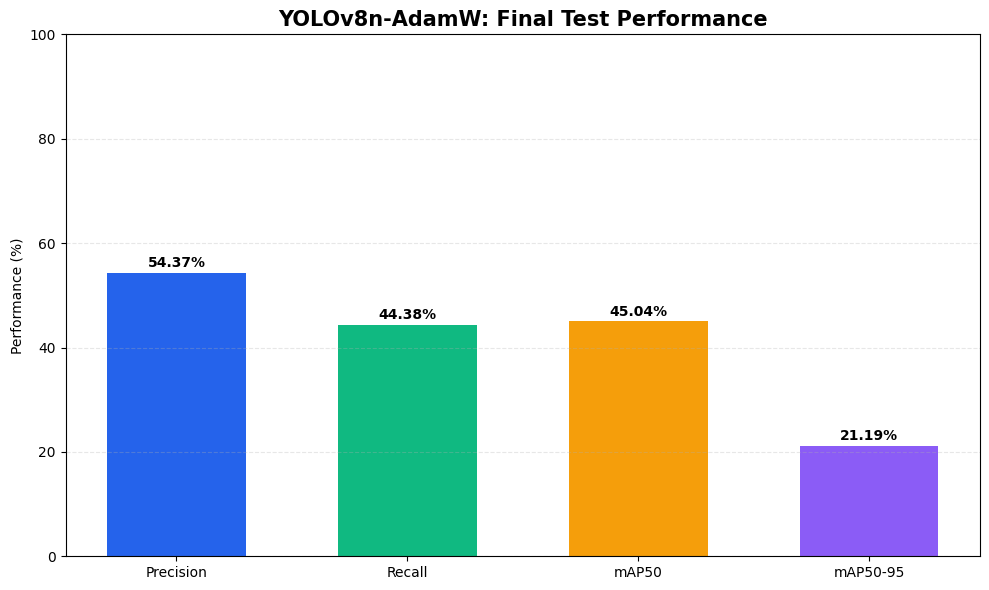


========== VALIDATION VS TEST ==========


,Metric,Validation (%),Test (%),Difference (pp)
0,Precision,51.80,54.37,2.57
1,Recall,44.27,44.38,0.11
2,mAP50,44.30,45.04,0.74
3,mAP50-95,20.81,21.19,0.39


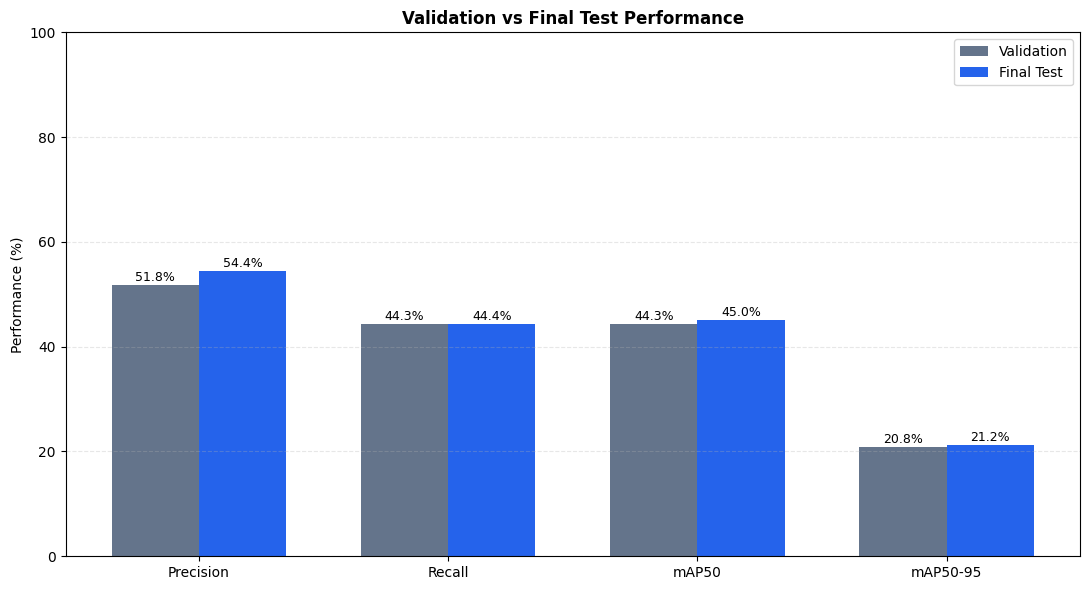

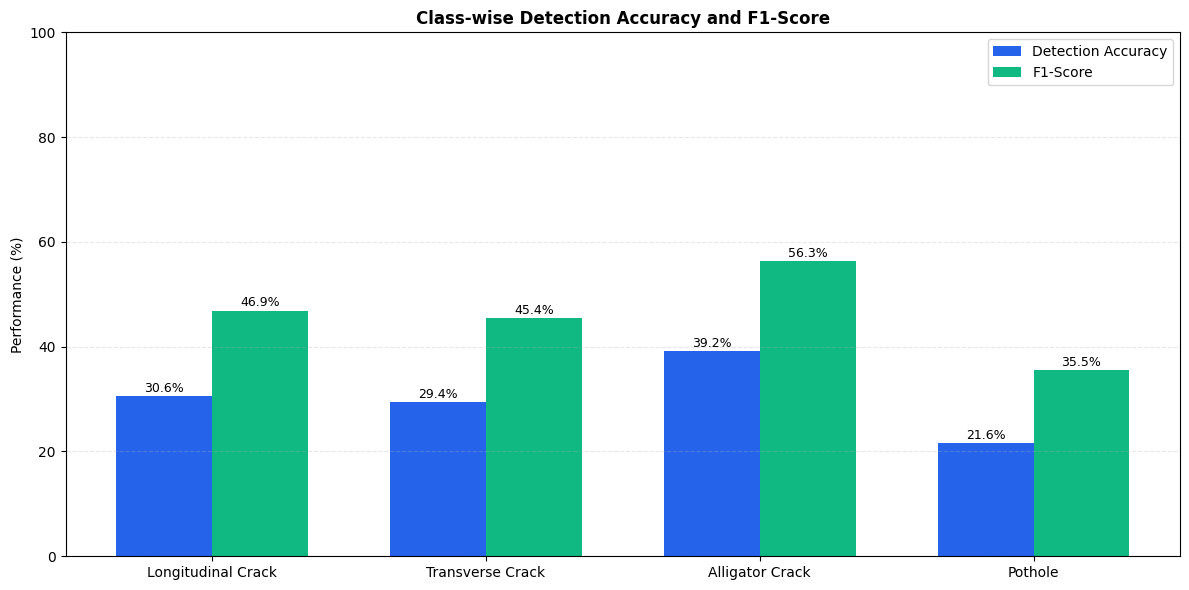


========== FINAL MODEL SAVED ==========
Model: /kaggle/working/Final_Test_Evaluation/Final_Model/best_model.pt
Model Size: 30.32 MB

========== ZIP BACKUP CREATED ==========
ZIP Path: /kaggle/working/Final_Test_Evaluation_16_Epochs.zip
ZIP Size: 31.21 MB

========== BACKUP VERIFICATION ==========
Verified: best_model.pt
Verified: model_selection.json
Verified: final_model_summary.csv
Verified: final_model_summary.json
Verified: final_test_performance.png
Verified: validation_vs_test.png
Verified: classwise_accuracy_f1.png
Verified: test_overall_metrics.csv
Verified: test_classwise_metrics.csv
Verified: detection_accuracy_overall.csv
Verified: detection_accuracy_classwise.csv
Verified: confusion_matrix.png
Verified: test_data.yaml

All important files verified!

========== CELL 6 COMPLETED ==========


In [8]:

# ==========================================
# NOTEBOOK 05 - CELL 6
# Final Results, Graphs and Backup
# ==========================================

import shutil
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# ==========================================
# 1. Create Final Summary Directory
# ==========================================

SUMMARY_DIR = PROJECT_DIR / "Final_Summary"

SUMMARY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("========== FINAL PROJECT SUMMARY ==========")

# ==========================================
# 2. Create Final Performance Summary
# ==========================================

final_summary = {

    "Model": "YOLOv8n-AdamW",

    "Completed Training Epochs": 16,

    "Test Images": int(processed_images),

    "Ground Truth Objects": int(total_tp + total_fn),

    "Predicted Objects": int(total_tp + total_fp),

    "Validation mAP50 (%)": round(
        selection_summary["mAP50"] * 100, 2
    ),

    "Validation mAP50-95 (%)": round(
        selection_summary["mAP50-95"] * 100, 2
    ),

    "Test Precision (%)": round(
        test_metrics.box.mp * 100, 2
    ),

    "Test Recall (%)": round(
        test_metrics.box.mr * 100, 2
    ),

    "Test mAP50 (%)": round(
        test_metrics.box.map50 * 100, 2
    ),

    "Test mAP50-95 (%)": round(
        test_metrics.box.map * 100, 2
    ),

    "Fixed Threshold Precision (%)": round(
        p * 100, 2
    ),

    "Fixed Threshold Recall (%)": round(
        r * 100, 2
    ),

    "Detection Accuracy (%)": round(
        acc * 100, 2
    ),

    "F1-Score (%)": round(
        f1 * 100, 2
    ),

    "Confidence Threshold": CONF_THRESHOLD,

    "Matching IoU Threshold": IOU_THRESHOLD,

    "True Positives": total_tp,

    "False Positives": total_fp,

    "False Negatives": total_fn,

    "Inference Time (ms/image)": round(
        test_metrics.speed["inference"], 3
    ),

    "Evaluation Time (min)": round(
        test_eval_time / 60, 2
    )
}

summary_df = pd.DataFrame([final_summary])

display(
    summary_df.T.rename(
        columns={0: "Final Result"}
    )
)

# Save CSV summary
summary_df.to_csv(

    SUMMARY_DIR / "final_model_summary.csv",

    index=False
)

# Save JSON summary
with open(
    SUMMARY_DIR / "final_model_summary.json",
    "w"
) as file:

    json.dump(
        final_summary,
        file,
        indent=4
    )

# ==========================================
# 3. Overall Test Performance Chart
# ==========================================

metric_names = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

metric_values = [

    test_metrics.box.mp * 100,

    test_metrics.box.mr * 100,

    test_metrics.box.map50 * 100,

    test_metrics.box.map * 100
]

plt.figure(figsize=(10, 6))

bars = plt.bar(

    metric_names,

    metric_values,

    color=[
        "#2563EB",
        "#10B981",
        "#F59E0B",
        "#8B5CF6"
    ],

    width=0.6
)

for bar, value in zip(
    bars, metric_values
):

    plt.text(

        bar.get_x() + bar.get_width() / 2,

        value + 1,

        f"{value:.2f}%",

        ha="center",

        fontweight="bold"
    )

plt.title(
    "YOLOv8n-AdamW: Final Test Performance",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Performance (%)")
plt.ylim(0, 100)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    SUMMARY_DIR / "final_test_performance.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

# ==========================================
# 4. Validation vs Test Comparison
# ==========================================

comparison_metrics = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

validation_values = [

    selection_summary["precision"] * 100,

    selection_summary["recall"] * 100,

    selection_summary["mAP50"] * 100,

    selection_summary["mAP50-95"] * 100
]

test_values = metric_values

comparison_df = pd.DataFrame({

    "Metric": comparison_metrics,

    "Validation (%)": validation_values,

    "Test (%)": test_values
})

comparison_df["Difference (pp)"] = (

    comparison_df["Test (%)"] -

    comparison_df["Validation (%)"]
)

comparison_df.to_csv(

    SUMMARY_DIR / "validation_vs_test.csv",

    index=False
)

print("\n========== VALIDATION VS TEST ==========")

display(comparison_df.round(2))

x = np.arange(len(comparison_metrics))
width = 0.35

plt.figure(figsize=(11, 6))

bars1 = plt.bar(

    x - width / 2,

    validation_values,

    width,

    label="Validation",

    color="#64748B"
)

bars2 = plt.bar(

    x + width / 2,

    test_values,

    width,

    label="Final Test",

    color="#2563EB"
)

for bars in [bars1, bars2]:

    for bar in bars:

        value = bar.get_height()

        plt.text(

            bar.get_x() + bar.get_width() / 2,

            value + 0.8,

            f"{value:.1f}%",

            ha="center",

            fontsize=9
        )

plt.xticks(x, comparison_metrics)

plt.ylabel("Performance (%)")

plt.title(
    "Validation vs Final Test Performance",
    fontweight="bold"
)

plt.ylim(0, 100)
plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    SUMMARY_DIR / "validation_vs_test.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

# ==========================================
# 5. Class-wise Accuracy and F1-Score
# ==========================================

class_names = accuracy_classwise[
    "Class Name"
].tolist()

class_accuracy = accuracy_classwise[
    "Detection Accuracy (%)"
].tolist()

class_f1 = accuracy_classwise[
    "F1-Score (%)"
].tolist()

x = np.arange(len(class_names))

plt.figure(figsize=(12, 6))

bars1 = plt.bar(

    x - width / 2,

    class_accuracy,

    width,

    label="Detection Accuracy",

    color="#2563EB"
)

bars2 = plt.bar(

    x + width / 2,

    class_f1,

    width,

    label="F1-Score",

    color="#10B981"
)

for bars in [bars1, bars2]:

    for bar in bars:

        value = bar.get_height()

        plt.text(

            bar.get_x() + bar.get_width() / 2,

            value + 0.8,

            f"{value:.1f}%",

            ha="center",

            fontsize=9
        )

plt.xticks(x, class_names)

plt.ylabel("Performance (%)")

plt.title(
    "Class-wise Detection Accuracy and F1-Score",
    fontweight="bold"
)

plt.ylim(0, 100)
plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    SUMMARY_DIR / "classwise_accuracy_f1.png",

    dpi=300,

    bbox_inches="tight"
)

plt.show()

# ==========================================
# 6. Save Selected Model
# ==========================================

FINAL_MODEL_DIR = PROJECT_DIR / "Final_Model"

FINAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_MODEL_PATH = (

    FINAL_MODEL_DIR / "best_model.pt"
)

shutil.copy2(

    MODEL_PATH,

    FINAL_MODEL_PATH
)

shutil.copy2(

    SELECTION_PATH,

    FINAL_MODEL_DIR / "model_selection.json"
)

print("\n========== FINAL MODEL SAVED ==========")

print("Model:", FINAL_MODEL_PATH)

print(
    f"Model Size: "
    f"{FINAL_MODEL_PATH.stat().st_size / 1024**2:.2f} MB"
)

# ==========================================
# 7. Create Backup Folder
# ==========================================

BACKUP_DIR = WORK_DIR / "Final_Test_Evaluation_Backup"

if BACKUP_DIR.exists():

    shutil.rmtree(BACKUP_DIR)

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Copy complete evaluation results
shutil.copytree(

    PROJECT_DIR,

    BACKUP_DIR / "Final_Test_Evaluation"
)

# Copy test dataset configuration
shutil.copy2(

    TEST_YAML_PATH,

    BACKUP_DIR / "test_data.yaml"
)

# ==========================================
# 8. Create ZIP Backup
# ==========================================

ZIP_BASE = WORK_DIR / "Final_Test_Evaluation_16_Epochs"

ZIP_PATH = shutil.make_archive(

    str(ZIP_BASE),

    "zip",

    root_dir=BACKUP_DIR
)

ZIP_PATH = Path(ZIP_PATH)

print("\n========== ZIP BACKUP CREATED ==========")

print("ZIP Path:", ZIP_PATH)

print(
    f"ZIP Size: "
    f"{ZIP_PATH.stat().st_size / 1024**2:.2f} MB"
)

# ==========================================
# 9. Verify Important Backup Files
# ==========================================

required_files = [

    "Final_Test_Evaluation/Final_Model/best_model.pt",

    "Final_Test_Evaluation/Final_Model/model_selection.json",

    "Final_Test_Evaluation/Final_Summary/final_model_summary.csv",

    "Final_Test_Evaluation/Final_Summary/final_model_summary.json",

    "Final_Test_Evaluation/Final_Summary/final_test_performance.png",

    "Final_Test_Evaluation/Final_Summary/validation_vs_test.png",

    "Final_Test_Evaluation/Final_Summary/classwise_accuracy_f1.png",

    "Final_Test_Evaluation/AdamW_Final_Test/test_overall_metrics.csv",

    "Final_Test_Evaluation/AdamW_Final_Test/test_classwise_metrics.csv",

    "Final_Test_Evaluation/AdamW_Final_Test/detection_accuracy_overall.csv",

    "Final_Test_Evaluation/AdamW_Final_Test/detection_accuracy_classwise.csv",

    "Final_Test_Evaluation/AdamW_Final_Test/confusion_matrix.png",

    "test_data.yaml"
]

print("\n========== BACKUP VERIFICATION ==========")

for file in required_files:

    file_path = BACKUP_DIR / file

    assert file_path.exists(), f"Missing: {file}"

    print("Verified:", file_path.name)

assert ZIP_PATH.exists()

print("\nAll important files verified!")

print("\n========== CELL 6 COMPLETED ==========")


## Step 7: Download Final Test Evaluation Backup

Download the complete final test evaluation archive
containing the selected trained model, performance
metrics, detection accuracy, evaluation plots,
and configuration files.

In [9]:
# ==========================================
# NOTEBOOK 05 - CELL 7
# Download Final Test Evaluation Backup
# ==========================================

import os

from IPython.display import FileLink, display

os.chdir("/kaggle/working")

print("========== DOWNLOAD FINAL BACKUP ==========")

display(
    FileLink(
        "Final_Test_Evaluation_16_Epochs.zip"
    )
)

========== DOWNLOAD FINAL BACKUP ==========


/kaggle/working/Final_Test_Evaluation_16_Epochs.zip